# How far bans and token vetoes push Qwen3-8B: token-walk demo

**Artifact** `art_ccAbfJVcv0LO` (experiment, iteration 3, step 4) · **Model** Qwen/Qwen3-8B, revision `b968826d`
(bf16 for the path tasks T1 grid path / T2 weighted shortest path; the official FP8 checkpoint for the bench tasks
T03 k-th smallest, T04 substring search, T06 find duplicate, T10 connected components) · thinking off,
temperature 1.0, no top-k / top-p, one fixed seed per program.

Ask Qwen3-8B for a grid path-finder and it writes BFS. Ask for the k-th smallest value and it sorts. The study asks
how far the model can be pushed off such a **default algorithm**, and by which tool:

* **(4b) Token walk.** The prompt never names an algorithm. Instead, a persistent per-request **logit veto**
  masks the default's *distinctive token n-gram* at decode time (for BFS on T1: ` c, path = queue.p`). The walk
  then repeats: see where the model lands, veto that landing too, and so on. Up to 2 extra mask rounds handle string
  leaks and re-emergence. Two controls: a matched **sham** n-gram veto, and (T1) a fixed **TOP5** veto.
* **(4a) Prompt reach.** Leave-one-survivor ban lists and two-step bans in the prompt, scored as *will* against
  forced *can*.
* **(4c) Long-form novelty.** The two 2,000-word "make a (fully) novel algorithm" instructions, with every program
  audited for novelty.

**Headline of the full run (1,750 token-walk programs).** The veto is exact: 0 banned-sequence occurrences in
1,450 vetoed generations. Yet the walk **stalled on all 6 tasks**: at step 1 on T1, T2, T03, T04 and T10, and at
step 2 on T06. The default came back in three ways: renamed (`current_row`), in non-canonical spellings (string
leaks up to 0.86), or as near-miss syntax (T1: 66-86 % invalid code). The matched sham veto kept the default
(T1 50/50, T2 50/50, T04 49/50, T10 44/44 valid), while the distinctive veto cut T2's pass rate from 50/50 to
19/46. In the prompt-reach arm, prediction C3 is disconfirmed. In the long-form arm, 0 of 575 outputs is a novel
algorithm.

**What this notebook runs.** `method.py` is the experiment's entry point. Its GPU stages (vLLM server; walk, ban
and long-form sampling; LLM judges) need an NVIDIA GPU and the 8B model, so the notebook does not re-run them. It
runs the CPU part on a curated subset of **100 of the 1,750 token-walk programs** (`mini_demo_data.json`):

1. the frozen protocol (`src/config.py`) and the neutral-twin prompts;
2. the logit veto (`src/veto.py`), first on a toy logits row, then replayed token by token over every stored
   vetoed generation. The replay checks that the veto was exact and re-detects the string leaks (`src/ngram.py`,
   `src/walk.py`);
3. the hash chain of commitments (`src/commit.py`);
4. `method.py outputs`: `assemble_outputs()` turns the per-program rows into the `token_walk` examples of
   `method_out.json`, and the result is checked against the stored examples;
5. the walk's per-round summaries (`walk.summarize`) and the original figures (`src/figures.py`), for the demo
   subset and for the full run.

Original code is copied verbatim. Each notebook change is named in the markdown above its cell. After the install
cell, everything runs in seconds.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru - NOT pre-installed on Colab, always install (method.py and src/config.py log through loguru)
_pip('loguru==0.7.3')

# numpy, matplotlib, torch - pre-installed on Colab, install locally only (Colab's exact versions; torch as CPU build)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'matplotlib==3.10.0')
    _pip('torch==2.9.0+cpu', '--extra-index-url', 'https://download.pytorch.org/whl/cpu')

In [2]:
from __future__ import annotations

# ---- method.py (verbatim)
import json
import subprocess
import sys
from collections import Counter
from pathlib import Path

from loguru import logger

# ---- src/config.py, commit.py, veto.py, ngram.py, walk.py, stats.py, figures.py (their imports, merged)
import hashlib
import math
import os
import random
from datetime import datetime, timezone
from typing import Any, Optional

import matplotlib.pyplot as plt
import torch

# ---- notebook only: show the saved figures inline
from IPython.display import Image, display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-3/experiment-18/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
EXAMPLES = data["datasets"][0]["examples"]
META = data["metadata"]
print(data["datasets"][0]["dataset"], "-", len(EXAMPLES), "of the", META["selection"]["n_full_run"],
      "Qwen3-8B token-walk programs;", META["selection"]["n_cells"], "cells (arm, task, step, mask round)")
print("per arm:", dict(Counter(e["arm"] for e in EXAMPLES)))
print("labels :", dict(Counter(e["label"] for e in EXAMPLES)))
print("selection:", META["selection"]["rule"])
print("\nfields of one program row:", sorted(EXAMPLES[0]))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
token_walk - 100 of the 1750 Qwen3-8B token-walk programs; 35 cells (arm, task, step, mask round)
per arm: {'walk': 77, 'sham': 15, 'fixed_top5': 8}
labels : {'bfs': 17, 'invalid': 13, 'dijkstra': 14, 'full_sort': 6, 'naive': 15, 'hash_set': 10, 'sort_adjacent': 4, 'other': 3, 'union_find': 6, 'quickselect': 4, 'floyd': 1, 'dfs': 6, 'builtin': 1}
selection: every (arm, task, step, round) cell gets 2 programs, the remaining 30 go round-robin to the headline cells (walk step 0 and step-1 round 0, sham, final TOP5 round); inside a cell programs are taken stratum by stratum over (label, passed, string_leak), most frequent stratum first, lowest sample index first; examples are ordered round-robin over the 35 cells

fields of one program row: ['arm', 'ast_label', 'code', 'code_sha256', 'condition', 'engine_dtype', 'finish_reason', 'fires', 'judge_label', 'label', 'labeller_source', 'leak_detail', 'model', 'n_

## Configuration

Every tunable size lives here. Each original value is in the comment beside its parameter.

* `N_PROGRAMS`: how many curated programs are used, taken from the front of the list. The list is ordered
  round-robin over the 35 cells, so `N_PROGRAMS = 35` covers every cell once. The smallest value that still
  produces every output is 2: the first T1 step-0 program plus the first vetoed one. The demo ships 100
  programs; the original walk used all 1,750, which `mini_demo_data.json` does not include.
* `N_REPLAY`: how many vetoed generations are replayed token by token through the veto (originally every one of
  the 1,450 vetoed generations was checked).
* `SHOW_CODE_CHARS`: how much program text the illustrations print.
* `DEMO_ROOT`: the folder where the original layout (`data/`, `predictions/`, `results/`, ...) is rebuilt.

In [5]:
N_PROGRAMS = 100          # curated token-walk programs used (demo max 100; original run: 1,750 = walk 1,400 + sham 200 + TOP5 150)
N_REPLAY = 100            # vetoed generations replayed token by token (original: all 1,450 vetoed generations)
SHOW_CODE_CHARS = 900     # characters of program text printed in the illustrations
DEMO_ROOT = Path("token_walk_demo")   # the original folder layout (data/, predictions/, results/, ...) is rebuilt here

## 1. The frozen protocol (`src/config.py`)

Every choice that more than one stage reads is frozen in this file:
* the model and its revision;
* decoding: temperature 1.0, no top-k / top-p, thinking off;
* the seed rule: one fixed seed per program, a function of task, step, round and index only;
* the five templates W1-W5 behind the neutral twins;
* the task registry: catalogue, default algorithm, signature, precision;
* the walk thresholds. A string-leak rate above 0.05, or a re-emergence of 0.20 or more, adds mask items for up to
  2 extra rounds. A step **STALLS** when it has fewer than 20 non-vetoed attempts or a vetoed share above 0.5.

Notebook changes: `ROOT` is `DEMO_ROOT`, because a notebook has no `__file__`. The `sys.path` lines are commented
out. `_fill_bench()` fills the bench rows of the task table from their `spec.json` files; it runs at import time in
the original, and here it runs in section 2, once those files are written.

In [6]:
"""Shared constants, paths and the task registry for Step 4 (token walk, prompt reach, long-form novelty).

Every frozen choice of the artifact plan that more than one stage reads lives here: task registry (catalogues,
defaults, display names, analysis sets), decoding, seeds, thresholds, model paths and the input locations.
"""

# (imports: see the imports cell)

ROOT = DEMO_ROOT.resolve()  # notebook: was Path(__file__).resolve().parent.parent (a notebook has no __file__)
SRC = ROOT / "src"
INPUTS = ROOT / "inputs"
DATA = ROOT / "data"
RESULTS = ROOT / "results"
PRED = ROOT / "predictions"
FIGS = ROOT / "figures"
LOGS = ROOT / "logs"
COMMIT_LOG = ROOT / "commitments.log"
for _d in (DATA, RESULTS, PRED, FIGS, LOGS):
    _d.mkdir(parents=True, exist_ok=True)

BENCH_DIR = INPUTS / "bench"          # copy of exp11 bench (frozen; verified against bench/commitment.json)
SUITE_DIR = INPUTS / "suite"          # copy of exp8 suite (exp1 canonical labeller + T1/T2 tasks)
# The declared dataset dependency (art_j3Rm_lr2nzR6, folder gen_art_dataset_1): read only by audit.py (corpus) and
# dep_usage.py.  DEP_DATASET_DIR overrides the default sibling-folder location of the published repository.
DEP_DATASET = Path(os.environ.get("DEP_DATASET_DIR", str(ROOT.parent / "gen_art_dataset_1")))

# notebook: nothing is imported from the source tree, so the sys.path lines are not needed
# for _p in (str(INPUTS), str(SUITE_DIR), str(SRC)):
#     if _p not in sys.path:
#         sys.path.insert(0, _p)

# ------------------------------------------------------------------------------------------------ models
MODEL_BF16 = "Qwen/Qwen3-8B"
MODEL_BF16_REV = "b968826d9c46dd6066d109eabc6255188de91218"
MODEL_FP8 = "Qwen/Qwen3-8B-FP8"
HF_HUB = Path(os.environ.get("HF_HUB_CACHE", str(Path.home() / ".cache/huggingface/hub")))


def model_dir(kind: str) -> str:
    if kind == "bf16":
        p = HF_HUB / "models--Qwen--Qwen3-8B" / "snapshots" / MODEL_BF16_REV
        return str(p) if p.exists() else MODEL_BF16
    snaps = sorted((HF_HUB / "models--Qwen--Qwen3-8B-FP8" / "snapshots").glob("*"))
    return str(snaps[-1]) if snaps else MODEL_FP8


SERVED = {"bf16": "qwen3-8b-bf16", "fp8": "qwen3-8b-fp8"}
PORTS = {"bf16": int(os.environ.get("S4_PORT_BF16", "8231")), "fp8": int(os.environ.get("S4_PORT_FP8", "8232"))}

# ------------------------------------------------------------------------------------------------ decoding
DECODING = {"temperature": 1.0, "top_p": 1.0, "top_k": -1, "min_p": 0.0, "repetition_penalty": 1.0}
MAX_TOKENS_SHORT = 1024
MAX_TOKENS_LONG = 4096
THINK_CAP = 16384
THINK_MAX_MODEL_LEN = 20480
THINK_STOP_PHRASE = ("\n\nConsidering the limited time by the user, I have to give the solution based on the thinking "
                     "directly now.\n</think>\n\n")
THINK_END_ID = 151668   # '</think>' in the Qwen3 vocabulary
IM_END_ID = 151645

# ------------------------------------------------------------------------------------------------ seeds
SEED_BASE = 20261021
TASK_IDX = {"T1": 0, "T2": 1, "T03": 2, "T04": 3, "T06": 4, "T10": 5}


def seed_walk(task: str, step: int, rnd: int, i: int) -> int:
    return SEED_BASE + 2_000_000 + 10_000 * TASK_IDX[task] + 1_000 * step + 100 * rnd + i


def seed_sham(task: str, rnd: int, i: int) -> int:
    return SEED_BASE + 2_500_000 + 10_000 * TASK_IDX[task] + 100 * rnd + i


def seed_top5(rnd: int, i: int) -> int:
    return SEED_BASE + 2_600_000 + 100 * rnd + i


def seed_los(task: str, s_idx: int, i: int) -> int:
    return SEED_BASE + 3_000_000 + 10_000 * TASK_IDX[task] + 1_000 * s_idx + i


def seed_two_step(task: str, i: int) -> int:
    return SEED_BASE + 4_000_000 + 10_000 * TASK_IDX[task] + i


def seed_long_off(task: str, prompt_idx: int, i: int, dtype_offset: int = 0) -> int:
    return SEED_BASE + 5_000_000 + 10_000 * TASK_IDX[task] + 1_000 * prompt_idx + 500 * dtype_offset + i


def seed_long_on(task: str, prompt_idx: int, i: int) -> int:
    return SEED_BASE + 6_000_000 + 10_000 * TASK_IDX[task] + 1_000 * prompt_idx + i


def seed_unit(i: int) -> int:
    return SEED_BASE + 9_000_000 + i


# ------------------------------------------------------------------------------------------------ templates
W_TEMPLATES = {
    "W1": "Do not use {N} for this task.",
    "W2": "Your solution must not rely on {N}.",
    "W3": "Avoid {N} entirely.",
    "W4": "{N} is not allowed here.",
    "W5": "Write a correct solution that does not use {N}.",
}
W_IDS = list(W_TEMPLATES)
FILLER = " ."   # exp7 neutral-padding filler

LF_PROMPTS = {
    "LF1": ("Make a new algorithm for this task. Before writing any code, write a design rationale of about 2,000 "
            "words that explains the idea, how it differs from every algorithm you know for this task, and why it "
            "is correct."),
    "LF2": ("Make a fully novel algorithm never seen before for this task. Before writing any code, write a design "
            "rationale of about 2,000 words that explains the idea, why no one has used it before, and why it is "
            "correct."),
}
LF_FORMAT = ("Use only the Python standard library. Give the rationale first, then exactly one ```python block "
             "containing solve.")

# ------------------------------------------------------------------------------------------------ tasks
# T1/T2 labels are the exp1 canonical suite labels (suite/common.py CATALOGUE); A* and greedy best-first share
# 'astar_gbfs', and 'dijkstra' on T1 is unit-weight Dijkstra.  Display names are exp7's v2 names as frozen in
# exp8 prompts/frozen_prompts.json.
TASKS: dict[str, dict[str, Any]] = {
    "T1": {"family": "path", "suite": "t1", "default": "bfs",
           "catalogue": ["bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra"],
           "display": {"bfs": "breadth-first search (BFS)", "dfs": "depth-first search (DFS)",
                       "bibfs": "bidirectional BFS", "iddfs": "iterative deepening DFS (IDDFS)",
                       "astar_gbfs": "A* search", "dijkstra": "unit-weight Dijkstra"},
           "signature": "def solve(grid, start, goal):", "dtype": "bf16"},
    "T2": {"family": "path", "suite": "t2", "default": "dijkstra",
           "catalogue": ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"],
           "display": {"dijkstra": "Dijkstra's algorithm", "bf_spfa": "Bellman-Ford or SPFA",
                       "bidijkstra": "bidirectional Dijkstra", "floyd": "Floyd-Warshall",
                       "dial": "Dial's bucket-queue algorithm"},
           "signature": "def solve(n, edges, s, t):", "dtype": "bf16"},
    "T03": {"family": "bench", "bench": "T03", "task_id": "T03_kth_smallest", "default": "full_sort",
            "analysis_set": ["full_sort", "quickselect", "size_k_heap", "counting_sort", "heapify_pop"],
            "signature": "def solve(nums, k):", "dtype": "fp8"},
    "T04": {"family": "bench", "bench": "T04", "task_id": "T04_substring_search", "default": "naive",
            "analysis_set": ["naive", "kmp", "rabin_karp", "builtin", "z_algorithm"],
            "signature": "def solve(haystack, needle):", "dtype": "fp8"},
    "T06": {"family": "bench", "bench": "T06", "task_id": "T06_find_duplicate", "default": "hash_set",
            "analysis_set": ["hash_set", "value_binary_search", "floyd", "sort_adjacent"],
            "signature": "def solve(nums):", "dtype": "fp8"},
    "T10": {"family": "bench", "bench": "T10", "task_id": "T10_connected_components", "default": "union_find",
            "analysis_set": ["bfs", "dfs", "union_find"],
            "signature": "def solve(n, edges):", "dtype": "fp8"},
}
PATH_TASKS = ["T1", "T2"]
BENCH_TASKS = ["T03", "T04", "T06", "T10"]
ALL_TASKS = PATH_TASKS + BENCH_TASKS
OFF_LABELS = ("other", "invalid")


def load_spec(task: str) -> dict[str, Any]:
    return json.loads((BENCH_DIR / TASKS[task]["task_id"] / "spec.json").read_text())


def _fill_bench() -> None:
    for t in BENCH_TASKS:
        s = load_spec(t)
        TASKS[t]["catalogue"] = [c["mode"] for c in s["catalogue"]]
        TASKS[t]["display"] = {c["mode"]: c["display_name"] for c in s["catalogue"]}
        TASKS[t]["description"] = s["description"]
        TASKS[t]["spec_text"] = s["spec_text"]
        TASKS[t]["aliases"] = s["aliases"]
        sig = s["signature"]
        TASKS[t]["signature"] = f"def {sig}:"


# _fill_bench()  # notebook: called in section 2, after the bench spec.json files are written

# ------------------------------------------------------------------------------------------------ thresholds
N_PER_TEMPLATE = 10            # 5 templates x 10 = 50 per walk step-round / LOS list
N_TWO_STEP_PER_TEMPLATE = 20   # 100 per task
WALK_MAX_STEPS = 5
WALK_MAX_EXTRA_ROUNDS = 2
LEAK_THRESHOLD = 0.05
REEMERGE_THRESHOLD = 0.20
STALL_MIN_NONVETOED = 20
STALL_VETOED_SHARE = 0.5
NGRAM_PRESENCE = 0.8
CO_VETO_SHARE = 0.5
C3_CAN_MIN = 0.7
C3_WILL_MAX = 0.10
C3_DISCONFIRM = 0.30
STEP0_MIN_DEFAULT = 0.8
OPENROUTER_OWN_CAP = 0.95      # stop at USD 0.95 of this artifact's own spend (plan: <= USD 1.0)


# ------------------------------------------------------------------------------------------------ utils
def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode()).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with Path(p).open("rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    for line in p.read_text().splitlines():
        if line.strip():
            try:
                out.append(json.loads(line))
            except json.JSONDecodeError:
                continue
    return out


def append_jsonl(p: Path, rows: list[dict[str, Any]]) -> None:
    with Path(p).open("a") as f:
        for r in rows:
            f.write(json.dumps(r) + "\n")


def write_json(p: Path, obj: Any) -> None:
    Path(p).parent.mkdir(parents=True, exist_ok=True)
    Path(p).write_text(json.dumps(obj, indent=1, default=str))


def cap_first(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


def setup_logging(name: str) -> None:
    from loguru import logger

    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")

## 2. The demo data, written into the original folder layout

The original code reads files:
* `data/samples_<arm>.jsonl`: one labelled row per program, with label, pass flag, code and veto statistics;
* `data/raw_<arm>.jsonl`: response text, generated token ids and the request's veto sequences;
* the committed masks and forecasts in `predictions/`, and `commitments.log`;
* `results/walk.json`, written by `method.py analyze`;
* the bench `spec.json` files.

This cell writes those files under `DEMO_ROOT` from `mini_demo_data.json`, so the original functions run with no
edits to their file handling. The program rows are the first `N_PROGRAMS` curated rows, verbatim. The 47 committed
files (masks, forecasts and the three hashed scripts `src/analysis.py`, `src/reach.py`, `src/rederive.py`) are
byte-identical copies; section 7 checks their hashes. `results/walk.json` is the full run's walk analysis, without
its AST-surface lists.

In [7]:
# the curated rows -> data/samples_<arm>.jsonl and data/raw_<arm>.jsonl (the two files walk.label_and_rows() wrote)
rows_used = EXAMPLES[:N_PROGRAMS]
RAW_KEYS = ("raw_text", "raw_token_ids", "raw_finish_reason", "raw_veto_seqs")
for arm in ("walk", "sham", "fixed_top5"):
    mine = [e for e in rows_used if e["arm"] == arm]
    (DATA / f"samples_{arm}.jsonl").write_text(
        "".join(json.dumps({k: v for k, v in e.items() if k not in RAW_KEYS}) + "\n" for e in mine))
    (DATA / f"raw_{arm}.jsonl").write_text("".join(json.dumps(
        {"sample_id": e["sample_id"], "arm": e["arm"], "task": e["task"], "text": e["raw_text"],
         "token_ids": e["raw_token_ids"], "finish_reason": e["raw_finish_reason"], "veto_seqs": e["raw_veto_seqs"]})
        + "\n" for e in mine))

# committed files (masks, forecasts, hashed scripts), byte for byte, and the hash-chain log
for rel, text in META["committed_files"].items():
    (ROOT / rel).parent.mkdir(parents=True, exist_ok=True)
    (ROOT / rel).write_bytes(text.encode("utf-8"))
COMMIT_LOG.write_bytes(META["commitments_log"].encode("utf-8"))

# bench task specs (read by _fill_bench) and the full-run walk results (read by assemble_outputs and the figures)
for tid, text in META["bench_specs"].items():
    (BENCH_DIR / tid).mkdir(parents=True, exist_ok=True)
    (BENCH_DIR / tid / "spec.json").write_bytes(text.encode("utf-8"))
write_json(RESULTS / "walk.json", META["walk_results_full"])

_fill_bench()  # src/config.py runs this at import time

print(f"{DEMO_ROOT}/: {len(rows_used)} programs", dict(Counter(e["arm"] for e in rows_used)),
      f"| {len(META['committed_files'])} committed files | {len(META['bench_specs'])} bench specs\n")
for t in ALL_TASKS:
    T = TASKS[t]
    print(f"{t:>3} {T['family']:>5} {T['dtype']:>4}  default {T['default']:<11} {T['signature']:<34} "
          f"catalogue {T['catalogue']}")

token_walk_demo/: 100 programs {'walk': 77, 'sham': 15, 'fixed_top5': 8} | 47 committed files | 4 bench specs

 T1  path bf16  default bfs         def solve(grid, start, goal):      catalogue ['bfs', 'dfs', 'bibfs', 'iddfs', 'astar_gbfs', 'dijkstra']
 T2  path bf16  default dijkstra    def solve(n, edges, s, t):         catalogue ['dijkstra', 'bf_spfa', 'bidijkstra', 'floyd', 'dial']
T03 bench  fp8  default full_sort   def solve(nums, k):                catalogue ['full_sort', 'size_k_heap', 'heapify_pop', 'quickselect', 'median_of_medians', 'counting_sort']
T04 bench  fp8  default naive       def solve(haystack, needle):       catalogue ['naive', 'kmp', 'rabin_karp', 'z_algorithm', 'bmh', 'builtin']
T06 bench  fp8  default hash_set    def solve(nums):                   catalogue ['hash_set', 'sort_adjacent', 'floyd', 'value_binary_search', 'index_marking']
T10 bench  fp8  default union_find  def solve(n, edges):               catalogue ['bfs', 'dfs', 'union_find', 'label_propagation']

## 3. The prompts: neutral twins (`src/prompts.py`)

The walk never names an algorithm in the prompt. Every request uses one of five **neutral twins** W1-W5: the
single-ban sentence of the default with the algorithm's name replaced by a neutral noun ("Do not use *man* for this
task."), then a blank line, then the frozen task spec. For the bench tasks the twin is padded with ` .` fillers to
the ban's chat-formatted token length (the exp7 rule). T1/T2 reuse exp8's frozen twins, asserted token-identical.
The token veto therefore acts on a prompt that is identical in length and form to the ban arms, minus the ban.

Notebook changes:
* The original `neutral_twins()` builds the twins with the Qwen3-8B tokenizer and chat template from the frozen
  exp8/bench prompt files. Here it returns the frozen result shipped in `mini_demo_data.json`.
* The original `walk.decode()` is `tokenizer().decode(ids)`. Here it applies the same byte-level BPE decode to a
  shipped slice of the vocabulary: the byte string of each of the 626 token ids that occur in the demo data. It
  reproduces the tokenizer's output for all 100 shipped generations.
* `ban_prompt()` and `longform_prompt()` build the prompt-reach and long-form prompts. This demo ships only the
  token-walk dataset, so they are not defined.

In [8]:
def neutral_twins(task: str) -> dict[str, dict[str, Any]]:
    # W1-W5 neutral twins of the single ban of the task's default (the walk's ban-free frame).
    # notebook: the frozen twins from mini_demo_data.json (src/prompts.py rebuilds them with the tokenizer)
    return META["neutral_twins"][task]


_VOCAB_BYTES = {int(k): bytes.fromhex(v) for k, v in META["vocab_slice"].items()}


def decode(ids: list[int]) -> str:
    # notebook: byte-level BPE decode over the shipped vocabulary slice (walk.decode = tokenizer().decode(ids))
    return b"".join(_VOCAB_BYTES[i] for i in ids).decode("utf-8", errors="replace")


for t in ("T1", "T03"):
    print(f"--- {t} (default: {TASKS[t]['display'][TASKS[t]['default']]}), twin segments:")
    for w in W_IDS:
        print(f"  {w}: {neutral_twins(t)[w]['segment']!r}")
print("\n--- full user text of the T1 / W1 twin:\n" + neutral_twins("T1")["W1"]["user_text"])

--- T1 (default: breadth-first search (BFS)), twin segments:
  W1: 'Do not use man, the house and the baby for this task.'
  W2: 'Your solution must not rely on man, the house and baby.'
  W3: 'Avoid man, the house and the baby entirely.'
  W4: 'Man, the house, the baby and car is not allowed here.'
  W5: 'Write a correct solution that does not use man, the house and baby.'
--- T03 (default: a full sort), twin segments:
  W1: 'Do not use man for this task. . .'
  W2: 'Your solution must not rely on man. . .'
  W3: 'Avoid man entirely. . .'
  W4: 'Man is not allowed here. . .'
  W5: 'Write a correct solution that does not use man. . .'

--- full user text of the T1 / W1 twin:
Do not use man, the house and the baby for this task.

Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; the character . is a free cell and the character # is a wall. s

## 4. The logit veto (`src/veto.py`)

A request carries its banned token-id sequences. For a banned sequence g = (t1 ... tn), the processor sets the
logit of tn to -inf whenever the last n-1 generated ids equal (t1 ... tn-1). One-token sequences are masked at every
step. This is vLLM's bad-words rule applied per request, so g can never occur in the output ids. Requests without a
veto get no processor, so step 0 and the prompt-ban arms sample exactly as they would without the plugin.

`walk.mask_item()` expands each mask item into its surface variants (`ngram.expand`): the n-gram as tokenized, and
the tokenizations of its text with a leading space, with a leading newline, and bare.

Notebook change: `NGramVeto` is the vLLM V1 adapter (`AdapterLogitsProcessor`, loaded with
`--logits-processors veto:NGramVeto`). It needs vLLM and a GPU, so it is kept below as comments. `parse_veto()` and
`RequestVeto`, the per-request callable that does the masking, are verbatim.

In [9]:
def parse_veto(value) -> list[tuple[int, ...]]:
    if not value:
        return []
    seqs = json.loads(value) if isinstance(value, str) else value
    out = []
    for s in seqs:
        t = tuple(int(x) for x in s)
        if t:
            out.append(t)
    return out


class RequestVeto:
    """Per-request callable (output_ids, logits_row) -> logits_row, masking in place."""

    def __init__(self, seqs: list[tuple[int, ...]]):
        self.singles = sorted({s[0] for s in seqs if len(s) == 1})
        by_prefix: dict[tuple[int, ...], set[int]] = {}
        for s in seqs:
            if len(s) >= 2:
                by_prefix.setdefault(tuple(s[:-1]), set()).add(s[-1])
        self.by_prefix = {k: sorted(v) for k, v in by_prefix.items()}
        self.lens = sorted({len(k) for k in self.by_prefix})
        self._single_t: Optional[torch.Tensor] = None
        self._cache: dict[tuple[int, ...], torch.Tensor] = {}

    def masked_ids(self, output_ids: list[int]) -> list[int]:
        """Pure-python twin of __call__ (used by the unit tests): ids masked at the next step."""
        out = set(self.singles)
        n = len(output_ids)
        for m in self.lens:
            if n >= m:
                out.update(self.by_prefix.get(tuple(output_ids[n - m:]), []))
        return sorted(out)

    def __call__(self, output_ids: list[int], logits: torch.Tensor) -> torch.Tensor:
        dev = logits.device
        if self.singles:
            if self._single_t is None or self._single_t.device != dev:
                self._single_t = torch.tensor(self.singles, dtype=torch.long, device=dev)
            logits.index_fill_(0, self._single_t, float("-inf"))
        n = len(output_ids)
        for m in self.lens:
            if n >= m:
                key = tuple(output_ids[n - m:])
                last = self.by_prefix.get(key)
                if last:
                    t = self._cache.get(key)
                    if t is None or t.device != dev:
                        t = torch.tensor(last, dtype=torch.long, device=dev)
                        self._cache[key] = t
                    logits.index_fill_(0, t, float("-inf"))
        return logits


# notebook: the vLLM adapter needs `from vllm.v1.sample.logits_processor import AdapterLogitsProcessor`
# class NGramVeto(AdapterLogitsProcessor):
#     """vLLM V1 adapter: one RequestVeto per request that carries extra_args['veto']."""
#
#     @classmethod
#     def validate_params(cls, params) -> None:  # vLLM >= 0.11 hook (optional)
#         ea = getattr(params, "extra_args", None) or {}
#         if "veto" in ea:
#             parse_veto(ea["veto"])
#
#     def is_argmax_invariant(self) -> bool:
#         return False
#
#     def new_req_logits_processor(self, params):
#         ea = getattr(params, "extra_args", None) or {}
#         seqs = parse_veto(ea.get("veto"))
#         if not seqs:
#             return None
#         return RequestVeto(seqs)

### The veto on a real mask

The mask below is the T1 step-1 mask: the distinctive n-gram of BFS, chosen against the reference programs of every
other algorithm. It was committed before its 50 samples. The cell builds the request's `RequestVeto` and feeds it a
logits row. After the first n-1 tokens of the n-gram, the n-th token's logit becomes -inf. After any other prefix,
nothing is masked.

In [10]:
m = json.loads((PRED / "walk_T1_s1_r0.json").read_text())
it = m["mask_items"][0]
print(f"vetoed {m['vetoed']} by its {it['kind']} n-gram {it['string']!r} (n = {len(it['ids'])}; present in "
      f"{it['info']['presence_refs']:.0%} of BFS references; max share in another algorithm's programs "
      f"{it['info']['score']:.3f}; {it['info']['n_candidates']} candidates, {it['info']['n_format_unsafe']} format-unsafe)")
for v in it["variants"]:
    print(f"  {v['variant']:>7}: {v['ids']}  {v['string']!r}")

rv = RequestVeto(parse_veto(json.dumps(m["veto_seqs"])))
g = it["ids"]
logits = torch.zeros(151936)                      # one logits row over the Qwen3 vocabulary
out = rv(list(g[:-1]), logits)                    # the model has just emitted the first n-1 tokens of the n-gram
print(f"\nafter the prefix {decode(g[:-1])!r}: masked {rv.masked_ids(list(g[:-1]))} = {decode(g[-1:])!r}, "
      f"logit {out[g[-1]].item()}, {int(torch.isinf(out).sum())} of {out.numel()} logits masked")
print(f"after the prefix {decode([1499, 15302])!r}: masked {rv.masked_ids([1499, 15302])}")

vetoed ['bfs'] by its distinctive n-gram ' c, path = queue.p' (n = 6; present in 82% of BFS references; max share in another algorithm's programs 0.039; 657 candidates, 371 format-unsafe)
        g: [272, 11, 1815, 284, 7177, 556]  ' c, path = queue.p'
  newline: [198, 66, 11, 1815, 284, 7177, 556]  '\nc, path = queue.p'
     bare: [66, 11, 1815, 284, 7177, 556]  'c, path = queue.p'

after the prefix ' c, path = queue': masked [556] = '.p', logit -inf, 1 of 151936 logits masked
after the prefix 'from collections': masked []


## 5. What is recorded for each vetoed generation (`src/ngram.py`, `src/walk.py`, `src/stats.py`)

When a batch comes back, `walk.label_and_rows()` stores three numbers per program, all computed from its generated
token ids:
* `veto_occurrences` (`ngram.occurrences`): how often a banned sequence occurs in the output ids. The veto
  guarantees 0.
* `fires` (`walk.fires`): the number of decoding steps at which a banned prefix had just been emitted, so the
  processor masked a continuation.
* `string_leak` (`ngram.string_leak`): set when the decoded text still contains the vetoed string's core although
  no banned id sequence occurs. That is a non-canonical tokenization; the walk adds the covering token spans to the
  mask in the next round.

`walk.summarize()` turns the 50 programs of one round into the statistics that drive the walk's decisions
(`WalkArm.consume`): label counts, pass rate with Wilson interval, re-emergence of vetoed algorithms, leak rate,
invalid share and Hill diversity. All of it is verbatim.

In [11]:
def occurrences(out_ids: list[int], seqs: list[list[int]]) -> int:
    n = 0
    for s in seqs:
        L = len(s)
        for i in range(len(out_ids) - L + 1):
            if out_ids[i:i + L] == s:
                n += 1
    return n


def leak_spans(text_ids: list[int], core: str, decode) -> list[list[int]]:
    """Minimal contiguous output-token spans whose decoded text contains `core` (the vetoed string)."""
    spans = []
    L = len(text_ids)
    i = 0
    while i < L:
        found = None
        for j in range(i + 1, min(L, i + 12) + 1):
            if core in decode(text_ids[i:j]):
                found = j
                break
        if found is None:
            i += 1
            continue
        # shrink from the left
        k = i
        while k + 1 < found and core in decode(text_ids[k + 1:found]):
            k += 1
        spans.append(text_ids[k:found])
        i = found
    uniq = []
    for s in spans:
        if s not in uniq:
            uniq.append(s)
    return uniq


def string_leak(text: str, out_ids: list[int], mask_items: list[dict[str, Any]], decode) -> dict[str, Any]:
    """A leak: the decoded output contains a vetoed string's core although none of its banned id sequences
    occurs in the generated ids (non-canonical tokenisation).  Returns per-item flags and covering spans."""
    leaks = []
    for it in mask_items:
        core = it["string"].strip()
        if len(core) < 3:
            continue
        if core in text and occurrences(out_ids, it["seqs"]) == 0:
            leaks.append({"string": it["string"], "core": core, "spans": leak_spans(out_ids, core, decode)})
    return {"leak": bool(leaks), "items": leaks}


def fires(out_ids: list[int], seqs: list[list[int]]) -> int:
    prefixes = {tuple(s[:-1]) for s in seqs if len(s) >= 2}
    lens = sorted({len(p) for p in prefixes})
    n = 0
    for p in range(1, len(out_ids) + 1):
        for m in lens:
            if p >= m and tuple(out_ids[p - m:p]) in prefixes:
                n += 1
                break
    return n


def summarize(rows: list[dict[str, Any]], vetoed: list[str]) -> dict[str, Any]:
    n = len(rows)
    labels = [r["label"] for r in rows]
    counts = Counter(labels)
    att = [r for r in rows if r["label"] != "invalid"]
    n_att = len(att)
    k_pass = sum(r["passed"] for r in att)
    nonv = [r for r in att if r["label"] not in vetoed]
    nonv_ok = [r for r in nonv if r["passed"]]
    land = Counter(r["label"] for r in nonv)
    land_ok = Counter(r["label"] for r in nonv_ok)
    reem = {a: (sum(r["label"] == a for r in att) / n_att if n_att else 0.0) for a in vetoed}
    nv_modal = Counter(r["label"] for r in rows if r["label"] not in vetoed).most_common(1)
    return {"n": n, "attempted": n_att, "counts": dict(counts), "pass_rate": k_pass / n_att if n_att else None,
            "pass_ci": wilson(k_pass, n_att), "landing": dict(land), "landing_correct": dict(land_ok),
            "n_nonvetoed_attempted": len(nonv), "vetoed_share": (sum(r["label"] in vetoed for r in att) / n_att)
            if n_att else None, "reemergence": reem, "modal_nonvetoed": nv_modal[0][0] if nv_modal else None,
            "modal_correct_nonvetoed": land_ok.most_common(1)[0][0] if land_ok else None,
            "hill_cc": hill1(land_ok.values()),
            "hill_cc_rarefied20": hill1_rarefied([r["label"] for r in nonv_ok], 20),
            "other_share": counts.get("other", 0) / n if n else None,
            "invalid_share": counts.get("invalid", 0) / n if n else None,
            "leak_rate": sum(bool(r.get("string_leak")) for r in rows) / n if n else None,
            "truncated_share": sum(r.get("finish_reason") == "length" for r in rows) / n if n else None,
            "veto_occurrences_total": sum(r.get("veto_occurrences", 0) for r in rows),
            "fires_mean": (sum(r.get("fires", 0) for r in rows) / n) if n else None,
            "per_template": {w: dict(Counter(r["label"] for r in rows if r["template"] == w)) for w in W_IDS}}


Z95 = 1.959964


def wilson(k: int, n: int, z: float = Z95) -> list[float]:
    if n == 0:
        return [0.0, 1.0]
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return [max(0.0, c - h), min(1.0, c + h)]


def hill1(counts: Iterable[int]) -> float:
    c = [x for x in counts if x > 0]
    n = sum(c)
    if n == 0:
        return 0.0
    h = -sum((x / n) * math.log(x / n) for x in c)
    return math.exp(h)


def hill1_rarefied(labels: list[str], depth: int = 20, draws: int = 200, seed: int = 0) -> float | None:
    if len(labels) < depth:
        return None
    rng = random.Random(seed)
    vals = [hill1(Counter(rng.sample(labels, depth)).values()) for _ in range(draws)]
    return sum(vals) / len(vals)

## 6. Replaying the veto over the stored generations

For each vetoed program in the demo subset, the cell below:
1. rebuilds the request's processor from its committed mask, `predictions/<arm>_<task>_s<step>_r<round>.json`;
2. replays the stored generation token by token, asking `RequestVeto.masked_ids` what was masked at each step. If
   the veto was exact, no emitted token was ever masked;
3. recomputes `veto_occurrences`, `fires` and `string_leak` with the functions above, and compares them with the
   values stored at generation time.

It also checks the frozen seed rule (`seed_walk`, `seed_sham`, `seed_top5` in section 1) against every program's
stored seed and against the seed list of its committed mask.

In [12]:
replay = []
for e in [e for e in rows_used if e["raw_veto_seqs"]][:N_REPLAY]:
    m = json.loads((PRED / f"{e['arm']}_{e['task']}_s{e['step']}_r{e['round']}.json").read_text())
    seqs = m["veto_seqs"]
    rv = RequestVeto(parse_veto(json.dumps(seqs)))
    ids = e["raw_token_ids"]
    steps_masked = [(p, rv.masked_ids(ids[:p])) for p in range(len(ids))]
    leak = string_leak(e["raw_text"], ids, m["mask_items"], decode)
    replay.append({"e": e, "mask": m, "steps_masked": steps_masked, "singles": rv.singles,
                   "emitted_masked": sum(ids[p] in mk for p, mk in steps_masked),
                   "occurrences": occurrences(ids, seqs), "fires": fires(ids, seqs), "leak": leak})


def seed_of(e):
    i = int(e["sample_id"].rsplit("|", 1)[1])
    if e["arm"] == "walk":
        return seed_walk(e["task"], e["step"], e["round"], i), i
    return (seed_sham(e["task"], e["round"], i) if e["arm"] == "sham" else seed_top5(e["round"], i)), i


seed_ok = 0
for e in rows_used:
    s, i = seed_of(e)
    committed = json.loads((PRED / f"{e['arm']}_{e['task']}_s{e['step']}_r{e['round']}.json").read_text())["seeds"]
    seed_ok += s == e["seed"] == committed[i]
print(f"seed rule: {seed_ok}/{len(rows_used)} programs carry seed = f(task, step, round, index), as committed")
print(f"replayed {len(replay)} vetoed generations ({sum(len(x['e']['raw_token_ids']) for x in replay)} tokens): "
      f"emitted-but-masked tokens {sum(x['emitted_masked'] for x in replay)}, banned-sequence occurrences "
      f"{sum(x['occurrences'] for x in replay)} (stored {sum(x['e']['veto_occurrences'] for x in replay)})")
print(f"fires recomputed = stored for {sum(x['fires'] == x['e']['fires'] for x in replay)}/{len(replay)}; "
      f"string leak recomputed = stored for {sum(x['leak']['leak'] == x['e']['string_leak'] for x in replay)}"
      f"/{len(replay)} ({sum(x['leak']['leak'] for x in replay)} leaks)")

seed rule: 100/100 programs carry seed = f(task, step, round, index), as committed
replayed 77 vetoed generations (14598 tokens): emitted-but-masked tokens 0, banned-sequence occurrences 0 (stored 0)
fires recomputed = stored for 77/77; string leak recomputed = stored for 77/77 (16 leaks)


### How the model routes around the veto

Three illustrations from the replay. With the default `N_PROGRAMS = 100` they show the following.
1. **Near-miss syntax.** After ` c, path = queue` the T1 step-1 veto masks `.p`. The model emits ` p`, then
   `opleft()`, which gives `queue popleft()`, a syntax error, and the program is labelled invalid. In the full run,
   all 151 invalid T1 step-1 programs (T1's 66-86 % invalid share) contain exactly this `queue popleft(` near-miss.
2. **String leaks.** The vetoed text comes back through other token sequences, which the id veto cannot see. T10's
   ` parent` returns as `(parent` and `parents`. T1's n-gram returns as ` c, path = queue.pop`, a different last
   token.
3. **The default, damaged.** The T2 program whose mask vetoes ` heap = [(0, s` writes `heap = [(0, 0)]`. It is
   still Dijkstra, now started from node 0, so it fails. In the full run, 15 of the 27 failing Dijkstra programs at
   T2 step 1, round 0 seed the heap with `(0, 0)`, and none of the 19 passing ones do. This is the main way the
   distinctive veto cut T2's pass rate from 50/50 to 19/46, while the sham kept it at 50/50.

In [13]:
fired = next((x for x in replay if x["fires"] > 0), None)
if fired:
    e, ids = fired["e"], fired["e"]["raw_token_ids"]
    print(f"[{e['sample_id']}] label {e['label']}, passed {e['passed']}: the veto fired at {fired['fires']} steps")
    # steps where a banned prefix had just been emitted (one-token sequences are masked at every step)
    for p, mk in [(p, mk) for p, mk in fired["steps_masked"] if set(mk) - set(fired["singles"])][:4]:
        print(f"  ...{decode(ids[max(0, p - 8):p])!r} -> masked {[decode([t]) for t in mk]}, emitted "
              f"{decode([ids[p]])!r}, continuing {decode(ids[p:p + 6])!r}")

print("\nstring leaks, first walk-arm leak per task (the vetoed text comes back through other token ids):")
shown = set()
for x in replay:
    e = x["e"]
    if x["leak"]["leak"] and e["arm"] == "walk" and e["task"] not in shown:
        shown.add(e["task"])
        for li in x["leak"]["items"]:
            banned = [s for s in x["mask"]["veto_seqs"] if decode(s).strip() == li["core"]]
            print(f"  [{e['sample_id']}] {e['label']}, passed {e['passed']}: vetoed {li['string']!r} as {banned}")
            print(f"      but the output contains {[decode(sp) for sp in li['spans']]} as {li['spans']}")

kept = next((x for x in replay if x["e"]["label"] == TASKS[x["e"]["task"]]["default"] and x["e"]["arm"] == "walk"),
            None)
if kept:
    e = kept["e"]
    print(f"\n[{e['sample_id']}] vetoed {kept['mask']['vetoed']} -> still labelled {e['label']!r} "
          f"(passed {e['passed']}; mask strings {[i['string'] for i in kept['mask']['mask_items']]}):\n")
    print(e["code"][:SHOW_CODE_CHARS])

[walk|T1||s1r0|0] label invalid, passed False: the veto fired at 1 steps
  ...'        r, c, path = queue' -> masked ['.p'], emitted ' p', continuing ' popleft()\n        if ('

string leaks, first walk-arm leak per task (the vetoed text comes back through other token ids):
  [walk|T04||s1r1|1] naive, passed True: vetoed '+len' as [[88382], [488, 2892], [198, 88382]]
      but the output contains ['+len'] as [[10, 2892]]
  [walk|T06||s2r0|0] hash_set, passed True: vetoed ' set' as [[738], [198, 746], [746]]
      but the output contains ['_set'] as [[2602]]
  [walk|T10||s1r0|0] invalid, passed False: vetoed ' parent' as [[2681], [198, 3765], [3765]]
      but the output contains ['(parent', 'parents', ' parents'] as [[12489], [25456], [6562]]
  [walk|T2||s1r2|0] dijkstra, passed False: vetoed ' dist[u]:\n' as [[1582, 21335, 10343], [198, 12211, 21335, 10343], [12211, 21335, 10343]]
      but the output contains [' dist[u]:'] as [[1582, 21335, 5669]]
  [walk|T1||s1r0|20] dfs, passed Tru

## 7. The commitment chain (`src/commit.py`)

Every mask, forecast and analysis script was written to disk and hash-chained in `commitments.log` before the
samples it governs, with chain = sha256(previous chain + file sha256). `verify_chain()` re-hashes every committed
file and re-links the chain, and `method.py outputs` stores the result in its metadata.

The demo wrote byte-identical copies of the 47 committed files, so the check should reproduce the full run's result
exactly: 49 entries, with one bad entry. That entry is the v1 hash of `src/analysis.py`, which was extended after its
commit (deviation D17). The edit appears as a new chain entry instead of being hidden, and `src/rederive.py`
re-derives every preregistered number independently.

In [14]:
def _last_chain() -> str:
    if not COMMIT_LOG.exists():
        return "0" * 64
    lines = [l for l in COMMIT_LOG.read_text().splitlines() if l.strip()]
    return json.loads(lines[-1])["chain"] if lines else "0" * 64


def commit_file(path: Path, label: str) -> dict[str, Any]:
    path = Path(path)
    h = sha256_file(path)
    prev = _last_chain()
    chain = hashlib.sha256((prev + h).encode()).hexdigest()
    rec = {"utc": utc_now(), "label": label, "path": str(path.relative_to(ROOT)), "sha256": h, "prev_chain": prev,
           "chain": chain}
    with COMMIT_LOG.open("a") as f:
        f.write(json.dumps(rec) + "\n")
    return rec


def commit_json(path: Path, obj: Any, label: str) -> dict[str, Any]:
    path = Path(path)
    if path.exists():
        raise FileExistsError(f"refusing to overwrite committed file {path}")
    write_json(path, obj)
    return commit_file(path, label)


def verify_chain() -> dict[str, Any]:
    prev = "0" * 64
    n, bad = 0, []
    if not COMMIT_LOG.exists():
        return {"n": 0, "ok": True, "bad": []}
    for line in COMMIT_LOG.read_text().splitlines():
        if not line.strip():
            continue
        r = json.loads(line)
        n += 1
        ok = r["prev_chain"] == prev and r["chain"] == hashlib.sha256((prev + r["sha256"]).encode()).hexdigest()
        p = ROOT / r["path"]
        file_ok = p.exists() and sha256_file(p) == r["sha256"]
        if not (ok and file_ok):
            bad.append({"label": r["label"], "path": r["path"], "chain_ok": ok, "file_ok": file_ok})
        prev = r["chain"]
    return {"n": n, "ok": not bad, "bad": bad, "head": prev}


vc = verify_chain()
print(json.dumps(vc, indent=1))
print("identical to the full run's metadata.commitments:", vc == META["full_run_commitments"])

{
 "n": 49,
 "ok": false,
 "bad": [
  {
   "label": "code sha256 analysis.py before bench ban samples",
   "path": "src/analysis.py",
   "chain_ok": true,
   "file_ok": false
  }
 ],
 "head": "a4f108d2a29f6406def1094b267273653b71f549fd0e9185527b170df7fece90"
}
identical to the full run's metadata.commitments: True


## 8. The entry point (`method.py`): stages and deviations

`uv run method.py <command>` runs one stage per command, in the order of the docstring below. Each GPU stage runs in
its own process (`run()` calls the project venv's Python on `src/<stage>.py`) and talks to a PID-managed vLLM
server: bf16 for T1/T2, the official FP8 checkpoint for the bench tasks. The default command, `outputs`, rebuilds
`method_out.json` from the saved data. It is the only command that runs in-process, and the one this notebook runs.

Notebook changes: the docstring becomes `__doc__` (printed by `main()` for `help`). `ROOT` and the `sys.path` line
come from section 1. The module-level imports are in the imports cell.

In [15]:
__doc__ = """Step 4 of iteration 3 on Qwen3-8B: how far can bans and token vetoes push?

  (4b) TOKEN WALK - cumulative persistent logit vetoes of each landed algorithm's distinctive token n-gram under
       the neutral twins (no ban text), with a matched SHAM veto and (T1) a fixed TOP5 veto as controls;
  (4a) PROMPT REACH - leave-one-survivor ban lists (bench) and two-step bans (all tasks) scored as 'will' against
       forced 'can', with the C3 prediction and a preregistered list-independence test;
  (4c) LONG-FORM NOVELTY - the request's two 2,000-word-rationale instructions, thinking off and on, every
       correct off-catalogue program audited by two blind judges plus a manual pass against human/known solutions.

Baselines in the same pipeline: step 0 (neutral twins, no veto) for every veto arm; the prompt-ban comparators for
the veto; the sham veto (matched random control); forced 'can' (capability ceiling).

Usage (the order actually run; see README.md):
  uv run method.py s0                      # input copies, SHA256SUMS, bench commitment check
  uv run method.py server bf16 start       # PID-managed vLLM server (bf16, max_model_len 4608)
  uv run method.py unit bf16               # veto unit tests u1-u4 + n-gram unit tests
  uv run method.py phase A                 # T1/T2 walk + shams + fixed-TOP5 (+ committed forecasts, two-step)
  uv run method.py longform bf16           # thinking-off long-form, bf16 branch (concurrently with phase A)
  uv run method.py server bf16 stop; uv run method.py server fp8 start
  uv run method.py phase B                 # bench walk + shams, LOS after step-1 commit, two-step after step 2
  uv run method.py longform fp8_off 50     # FP8 cross-check copy + bench long-form
  uv run method.py longform fp8_on T1:10,T2:10
  uv run method.py audit corpus|controls|pool|claims
  uv run method.py analyze                 # results/*.json + figures
  uv run method.py outputs                 # method_out.json (+ full/mini/preview); also the default with no argument
"""

# ROOT = Path(__file__).resolve().parent    # notebook: ROOT (= DEMO_ROOT) is set in section 1
# sys.path.insert(0, str(ROOT / "src"))     # notebook: the src/ functions are defined in sections 1-7

PY = str(ROOT / ".venv" / "bin" / "python")


def run(args: list[str]) -> None:
    logger.info("$ " + " ".join(args))
    subprocess.run([PY] + args, cwd=str(ROOT), check=True)

`DEVIATIONS` lists the 17 documented departures from the plan, and `assemble_outputs()` stores the list in the
metadata. Several explain what the demo data shows:
* D3: distinctive n-grams must be lexical. After unit test u1, any n-gram containing a whitespace-only token is
  excluded, because the model bypassed one by re-indenting.
* D4: sham controls exist for T1, T2, T04 and T10 only.
* D7 / D16: the walk stalled at step 1, so the rung-2 forecasts come from the flagged fallback chain.
* D17: the `analysis.py` edit that section 7 shows.

In [16]:
DEVIATIONS = [
    {"id": "D1", "what": "Hardware: NVIDIA L4 (23 GB, 300 GB/s) instead of the planned RTX A4500 (20 GB, 640 GB/s); "
                         "6 CPUs (cgroup quota 5.1), 57 GB RAM.",
     "consequence": "bf16 decode measured at ~250-410 tok/s for short programs and ~84 tok/s (shared GPU) for long-form."},
    {"id": "D2", "what": "Precision by task family instead of bf16 for every short arm: T1/T2 arms in bf16 (their "
                         "reference programs and 'can' came from bf16 exp8/exp9), bench arms (T03/T04/T06/T10) on the "
                         "official Qwen3-8B-FP8 checkpoint (their pilot programs, forced programs and 'can' came from "
                         "FP8 exp11), weight-only FP8 Marlin kernels (no C compiler for Triton).",
     "consequence": "each family is compared with references of its own precision; the bf16-vs-FP8 cross-check on "
                    "LF1-T2 bounds the precision effect for one task only."},
    {"id": "D3", "what": "Distinctive n-gram candidates must be lexical: an n-gram containing a whitespace-only token "
                         "(indentation / newline) is format-unsafe. Added after veto unit test u1: the first choice for "
                         "T2 (' dist[u]:\\n' + 11 spaces) was bypassed by re-indenting in 20/20 samples.",
     "consequence": "the plan's selection rule (argmin max collateral; ties -> smaller n) is otherwise unchanged."},
    {"id": "D4", "what": "Sham n-grams may not contain a Python keyword or the fence tag 'python' (a keyword veto breaks "
                         "syntax) and may not equal the distinctive n-gram; bench shams for T03 and T06 are reported as "
                         "NOT_CONSTRUCTIBLE (no algorithm-generic n-gram exists in their 3-6-line default programs); "
                         "T04 and T10 shams were run.",
     "consequence": "sham controls exist for T1, T2, T04, T10."},
    {"id": "D5", "what": "Unit test u2 compares no-veto requests alone vs interleaved with vetoed rows on the same "
                         "server (17/20 token-identical); a processor-free engine was not loaded (a second ~6 min load).",
     "consequence": "u2 measures plugin/batch invariance and vLLM batch nondeterminism together."},
    {"id": "D6", "what": "Forecast commits per family: the path forecasts were committed after T1/T2 walk step 1 "
                         "(bf16 phase), the bench forecasts after the bench walk step 1 (FP8 phase); each precedes every "
                         "ban sample it scores.",
     "consequence": "the commit is not a single six-task commit, but no forecast follows its samples."},
    {"id": "D7", "what": "T1 and T2 walks STALLED at step 1, so R2 for their two-step bans came from the plan's fallback "
                         "chain (no non-default catalogue label had >= 5 attempts) = the realised exp8/exp9 single-ban "
                         "substitutes (T1 DFS, T2 BF/SPFA), flagged.",
     "consequence": "the path two-step bans replicate the iteration-1 two-step design."},
    {"id": "D8", "what": "A client bug (an asyncio semaphore bound to the first event loop) crashed phase A when the "
                         "two-step batch was queued; no sample of that batch had been generated or written; the "
                         "two-step bans were run by `phases.py two_step path bf16` from the committed forecasts.",
     "consequence": "none on the data (same seeds, same prompts)."},
    {"id": "D9", "what": "Long-form thinking-off took the plan's 'split' branch (stage-10 projection 220 min > 60 min, "
                         "measured while sharing the GPU): bf16 LF1-T2 N=50, LF2-T2/LF1-T1/LF2-T1 N=25; FP8 cross-check "
                         "copy LF1-T2 N=50 and the bench cells on FP8.",
     "consequence": "T1/T2 LF cells other than LF1-T2 have N=25."},
    {"id": "D10", "what": "Optional O1 (manifold placement) and O2 (5b temperature sweep) dropped first, as the drop "
                          "order prescribes, because the L4 throughput left no room.",
     "consequence": "no internal-state claim of any kind."},
    {"id": "D11", "what": "exp9 forced labels (extended labeller) mapped onto the suite labels for T1 (astar and gbfs -> "
                          "astar_gbfs, dijkstra_unit -> dijkstra); T2 'can' for bidijkstra and dial taken from exp7 plain "
                          "attempts because exp9 ran only descriptive variants for them.",
     "consequence": "documented in results/can.json; both values are far below the C3 threshold of 0.7."},
    {"id": "D12", "what": "ASSOCIATE forecasts are unavailable for the path tasks (no association answers exist in the "
                          "path inputs).", "consequence": "the path two-step bans are scored against WALK2/SNAPBACK only."},
    {"id": "D13", "what": "Audit judge controls (T5) failed at round 0 (A 2/6, B 3/6; results/audit_controls_round0_failed"
                          ".json) because the audit prompt did not say the programs had been labelled 'other' by the "
                          "automatic labeller, and two controls were debatable (Counter-counting is a hash approach; "
                          "Sunday search is Horspool-like and T04's catalogue has BMH). The prompt gained that context "
                          "and a decision order (miss, degenerate, known variant, novel); the two controls were replaced "
                          "(hard-coded shortcut; value-range bisection). Round 1: A 5/6, B 5/6 (both call value-range "
                          "bisection a labeller miss). Judge models unchanged.",
     "consequence": "the audit ran with the round-1 prompt only."},
    {"id": "D14", "what": "Thinking-on: the floor (T1/T2, N=10 per prompt) ran; the first extension process (T1/T2 to N=25 plus bench T03/T04/T06 at N=10) was stopped after ~6 min when the KV cache saturated and nothing of it was written; the bench cells (N=10 per prompt) were re-launched alone after the thinking-off jobs ended and completed; the T1/T2 extension to N=25 was not re-run.",
     "consequence": "thinking-on cells have N=10 per prompt (upper bound on the novel rate ~26% per cell)."},
    {"id": "D15", "what": "The bf16 long-form job was restarted once with higher concurrency after the walk ended (its "
                          "stage-10 samples were kept; the interrupted batch had written nothing). The labeller-judge "
                          "client gained retries on HTTP 429/5xx after one rate-limit failure in phase B (that program "
                          "fell back to its runtime label, as the frozen combine rule prescribes).",
     "consequence": "none on the data."},
    {"id": "D16", "what": "Forecasts for the reach tests were committed per family before the samples they score; the "
                          "two disconfirming C3 cells (T03 quickselect, T10 BFS) got 'rung >= 3' from the flagged "
                          "fallback R2 because the walk stalled at step 1; a post hoc sensitivity with rung 2 := the "
                          "association answer is reported beside the preregistered verdict.",
     "consequence": "the preregistered verdict stands; the sensitivity shows which cell depends on the rung rule."},
    {"id": "D17", "what": "src/analysis.py was extended AFTER its sha256 was committed before the bench ban samples "
                          "(commitments.log line 42): labeller-miss-corrected compositions (required by the plan), the "
                          "post hoc association-rung sensitivity, the mechanism-level claim check and a Holm-family "
                          "note. No preregistered computation changed (will, the C3 cell/overall rule, the "
                          "list-independence permutation test). The committed bytes were not kept (no version control "
                          "here), so the v1 entry fails the file check in metadata.commitments; the extended file is "
                          "committed as a new chain entry, and src/rederive.py - written before that commit and never "
                          "edited - recomputes every preregistered number from raw rows with 0 mismatches.",
     "consequence": "the chain shows the edit instead of hiding it; the preregistered numbers are independently "
                    "re-derived."},
]


for d in DEVIATIONS:
    print(f"{d['id']:>4}: {d['what'][:150]}{'...' if len(d['what']) > 150 else ''}")

  D1: Hardware: NVIDIA L4 (23 GB, 300 GB/s) instead of the planned RTX A4500 (20 GB, 640 GB/s); 6 CPUs (cgroup quota 5.1), 57 GB RAM.
  D2: Precision by task family instead of bf16 for every short arm: T1/T2 arms in bf16 (their reference programs and 'can' came from bf16 exp8/exp9), bench ...
  D3: Distinctive n-gram candidates must be lexical: an n-gram containing a whitespace-only token (indentation / newline) is format-unsafe. Added after veto...
  D4: Sham n-grams may not contain a Python keyword or the fence tag 'python' (a keyword veto breaks syntax) and may not equal the distinctive n-gram; bench...
  D5: Unit test u2 compares no-veto requests alone vs interleaved with vetoed rows on the same server (17/20 token-identical); a processor-free engine was n...
  D6: Forecast commits per family: the path forecasts were committed after T1/T2 walk step 1 (bf16 phase), the bench forecasts after the bench walk step 1 (...
  D7: T1 and T2 walks STALLED at step 1, so R2 for their two-step 

## 9. `method.py outputs`: from per-program rows to `method_out.json`

`assemble_outputs()` reads the per-program rows and turns each into one example of the experiment's output schema
(`input`, `output`, `predict_*`, `metadata_*`):
* **token_walk** covers the walk, sham and fixed-TOP5 rows. `input` is the neutral twin the program was sampled
  under, and `output` is `label|pass`. `predict_baseline_default` is the task's default.
  `predict_committed_forecast` is the forecast committed before the sample: the default at step 0, rung 2 from
  `predictions/reach_forecasts_<family>.json` at a vetoed step, the default for the sham (it should survive), and
  n/a for fixed TOP5.
* **prompt_reach**, **long_form** and **audit** are built the same way from their own rows. The demo ships only
  token-walk rows, so these blocks find nothing and are skipped, as in the original.

It then collects the metadata (versions, decoding, the walk summary, every `results/*.json`, the deviations and the
hash-chain check) and writes `method_out.json`.

Notebook change: the three `from <module> import ...` lines inside the function are commented out; the functions
are defined above, and `can_table` is imported but unused. Everything else is verbatim. Results files the demo does
not ship (`c3.json`, `reach.json`, ...) come back as `None` from `rj()`, as when the original runs before
`analyze`.

In [17]:
def assemble_outputs() -> None:
    # from prompts import ban_prompt, longform_prompt, neutral_twins  # notebook: neutral_twins is defined in
    #     section 3; ban_prompt / longform_prompt only serve prompt_reach / long_form rows (not shipped)
    # from programs import can_table  # notebook: imported but not used by assemble_outputs

    # Committed forecasts that every example is scored against (predict_* fields, strings):
    #   predict_baseline_default    - the unconstrained baseline: the task's default algorithm (step 0, no veto/ban);
    #   predict_committed_forecast  - the forecast committed before the example's samples (walk: rung 2 = the landing
    #                                 after the default is vetoed; sham: the default survives; fixed TOP5: 'n/a');
    #   predict_survivor / predict_c3 (LOS rows) - the only allowed algorithm / C3's 'will <= 0.10' forecast;
    #   predict_walk2 / predict_associate / predict_snapback (two-step rows) - the three committed forecasts;
    #   predict_judge_a_code_mechanism / predict_judge_a_claims_novelty (long-form rows) - claim extraction (judge A).
    rung2, c3q = {}, {}
    for g in ("path", "bench"):
        p = PRED / f"reach_forecasts_{g}.json"
        if p.exists():
            for t, v in json.loads(p.read_text())["tasks"].items():
                rung2[t] = v["rung_table"]["R2"]["R2"]
                for c in v["c3_cells"]:
                    c3q[(t, c["S"])] = c["qualifies"]
    claims = {}
    cpath = RESULTS / "claims.json"
    if cpath.exists():
        claims = {r["sample_id"]: (r.get("A") or {}) for r in json.loads(cpath.read_text())["records"]}

    def default_of(t):
        return TASKS[t]["default"]

    def ex_walk(r):
        tw = neutral_twins(r["task"])
        t = r["task"]
        if r["arm"] == "walk":
            fcst = default_of(t) if (r.get("step") or 0) == 0 else str(rung2.get(t))
        elif r["arm"] == "sham":
            fcst = default_of(t)
        else:
            fcst = "n/a"
        return {"input": tw[r["template"]]["user_text"], "output": f"{r['label']}|{'pass' if r['passed'] else 'fail'}",
                "predict_baseline_default": default_of(t), "predict_committed_forecast": fcst,
                "metadata_task": r["task"], "metadata_arm": r["arm"], "metadata_step": r.get("step"),
                "metadata_round": r.get("round"), "metadata_template": r["template"], "metadata_seed": r["seed"],
                "metadata_n_veto_seqs": r.get("n_veto_seqs"), "metadata_veto_occurrences": r.get("veto_occurrences"),
                "metadata_fires": r.get("fires"), "metadata_string_leak": r.get("string_leak"),
                "metadata_engine_dtype": r["engine_dtype"], "metadata_labeller_source": r["labeller_source"],
                "metadata_code_sha256": r["code_sha256"], "metadata_code": r.get("code"),
                "metadata_finish_reason": r.get("finish_reason"), "metadata_thinking": False}

    fc = {}
    for g in ("path", "bench"):
        p = PRED / f"two_step_forecasts_{g}.json"
        if p.exists():
            fc.update(json.loads(p.read_text())["tasks"])

    def ex_ban(r):
        bp = ban_prompt(r["task"], r["template"], r["meta_banned"])
        e = {"input": bp["user_text"], "output": f"{r['label']}|{'pass' if r['passed'] else 'fail'}",
             "predict_baseline_default": default_of(r["task"]),
             "metadata_task": r["task"], "metadata_arm": r["arm"], "metadata_condition": r["condition"],
             "metadata_banned": r["meta_banned"], "metadata_template": r["template"], "metadata_seed": r["seed"],
             "metadata_engine_dtype": r["engine_dtype"], "metadata_labeller_source": r["labeller_source"],
             "metadata_code_sha256": r["code_sha256"], "metadata_code": r.get("code"), "metadata_thinking": False}
        if r["arm"] == "los":
            surv = r["condition"].split("LOS(", 1)[1].rstrip(")")
            e["predict_survivor"] = surv
            e["predict_c3"] = (f"not {surv} (will<=0.10)" if c3q.get((r["task"], surv)) else "n/a (not a C3 cell)")
        if r["arm"] == "two_step" and r["task"] in fc:
            f = fc[r["task"]]
            e["predict_walk2"] = str(f["WALK2"].get("top1"))
            e["predict_associate"] = str(f["ASSOCIATE"]["for_R2"].get("label"))
            e["predict_snapback"] = str(f["SNAPBACK"]["top1"])
        return e

    def ex_lf(r):
        a = claims.get(r["sample_id"], {})
        return {"input": longform_prompt(r["task"], r["prompt_id"]),
                "output": f"{r['label']}|{'pass' if r['passed'] else 'fail'}",
                "predict_baseline_default": default_of(r["task"]),
                "predict_judge_a_code_mechanism": str(a.get("code_mechanism_guess")),
                "predict_judge_a_claims_novelty": str(a.get("claims_novelty")), "metadata_task": r["task"],
                "metadata_arm": "longform", "metadata_prompt_id": r["prompt_id"], "metadata_thinking": r["thinking"],
                "metadata_engine_dtype": r["engine_dtype"], "metadata_seed": r["seed"],
                "metadata_rationale_words": r.get("rationale_words"), "metadata_thinking_tokens": r.get("thinking_tokens"),
                "metadata_thinking_complete": r.get("thinking_complete"), "metadata_extract_method": r.get("extract_method"),
                "metadata_code_sha256": r["code_sha256"], "metadata_code": r.get("code"),
                "metadata_finish_reason": r.get("finish_reason")}

    datasets = []
    walk_rows = read_jsonl(DATA / "samples_walk.jsonl") + read_jsonl(DATA / "samples_sham.jsonl") + \
        read_jsonl(DATA / "samples_fixed_top5.jsonl")
    if walk_rows:
        datasets.append({"dataset": "token_walk", "examples": [ex_walk(r) for r in walk_rows]})
    ban_rows = read_jsonl(DATA / "samples_los.jsonl") + read_jsonl(DATA / "samples_two_step.jsonl")
    if ban_rows:
        datasets.append({"dataset": "prompt_reach", "examples": [ex_ban(r) for r in ban_rows]})
    lf_rows = read_jsonl(DATA / "samples_longform.jsonl")
    if lf_rows:
        datasets.append({"dataset": "long_form", "examples": [ex_lf(r) for r in lf_rows]})
    na = json.loads((RESULTS / "novelty_audit.json").read_text()) if (RESULTS / "novelty_audit.json").exists() else {}
    if na.get("records"):
        datasets.append({"dataset": "audit", "examples": [
            {"input": r.get("code") or "", "output": str(r.get("final_class")), "metadata_task": r["task"],
             "metadata_arm": r["arm"], "metadata_sample_id": r["sample_id"], "metadata_audit_role": r["audit_role"],
             "predict_judge_a": str(r["judge_A"].get("class")), "predict_judge_b": str(r["judge_B"].get("class")),
             "metadata_manual": r.get("manual"), "metadata_neighbours_known": r.get("neighbours_known")}
            for r in na["records"]]})

    def rj(name):
        p = RESULTS / name
        return json.loads(p.read_text()) if p.exists() else None

    # from commit import verify_chain  # notebook: defined in section 7
    import importlib.metadata as im

    versions = {}
    for pkg in ("vllm", "torch", "transformers", "numpy", "scipy"):
        try:
            versions[pkg] = im.version(pkg)
        except im.PackageNotFoundError:
            versions[pkg] = None
    walk = rj("walk.json") or {}
    meta = {
        "method_name": "Token-walk logit vetoes vs prompt bans vs long-form novelty instructions (Qwen3-8B)",
        "artifact_plan_id": "gen_plan_experiment_6_idx7", "utc": utc_now(), "model": "Qwen/Qwen3-8B (+ official FP8)",
        "model_revision_bf16": "b968826d9c46dd6066d109eabc6255188de91218", "versions": versions,
        "hardware_branch": "L4 23 GB (between the plan's 20 GB and >=24 GB branches); precision by family (D2)",
        "decoding": {"temperature": 1.0, "top_p": 1.0, "top_k": -1, "min_p": 0.0, "max_tokens_short": 1024,
                     "max_tokens_long": 4096, "think_cap": 16384},
        "baseline_vs_method": {"baselines": ["step 0 neutral twins (no veto) per veto arm", "prompt bans (LOS lists, "
                                             "two-step bans, exp9 TOP5/T2 LOS)", "sham n-gram veto (matched control)",
                                             "forced 'can' (capability ceiling)"],
                               "methods": ["persistent distinctive n-gram veto walk", "fixed TOP5 veto",
                                           "long-form novelty instructions (thinking off / on)"]},
        "walk": {t: {k: v for k, v in (walk.get(t) or {}).items() if k in ("status", "rungs", "deepest_rung_reached",
                                                                            "vetoed", "sham_vs_distinctive")}
                 for t in ALL_TASKS},
        "fixed_top5_T1": walk.get("fixed_top5_T1"), "c3": rj("c3.json"), "reach": rj("reach.json"),
        "list_independence": rj("list_independence.json"), "disguise": rj("disguise.json"),
        "longform": rj("longform.json"), "fp8_crosscheck": rj("fp8_crosscheck.json"),
        "novelty_audit_summary": {k: v for k, v in (na or {}).items() if k != "records"},
        "audit_controls": rj("audit_controls.json"), "can": rj("can.json"),
        "labeller_recheck": rj("labeller_recheck.json"), "veto_unit_tests": {k: rj(f"veto_unit_tests_{k}.json")
                                                                            for k in ("bf16", "fp8")},
        "inputs_check": rj("inputs_check.json"), "known_solutions": rj("known_solutions_summary.json"),
        "costs": rj("costs.json"), "longform_branch": rj("longform_branch.json"),
        "dependency_usage": rj("dependency_usage.json"), "labeller_recheck_note": "runtime vs adjudicated on gold",
        "rederive": rj("rederive.json"), "deviations": DEVIATIONS, "not_run": rj("not_run.json"),
        "commitments": verify_chain(),
        "c1_events_note": "this artifact has no C1 event types (modal, present_minor, exposure), so it writes no "
                          "results/c1_events.jsonl; per-event rows are in results/reach_events.jsonl",
        "headline_rule": "'no instruction or knob in this artifact produced a correct novel algorithm' only if the final "
                         "NOVEL count over ALL arms is 0",
        "novel_count_all_arms": len((na or {}).get("novel", [])),
    }
    out = {"metadata": meta, "datasets": datasets}
    (ROOT / "method_out.json").write_text(json.dumps(out, indent=1, default=str))
    logger.info(f"method_out.json: {sum(len(d['examples']) for d in datasets)} examples in {len(datasets)} datasets")

## 10. Running it: `main()` with `help` and `outputs`

`main()` is verbatim. A notebook has no command line, so `sys.argv` is patched around the calls. `help` prints the
docstring, and `outputs` runs `assemble_outputs()`. The other commands (`s0`, `server`, `unit`, `phase`,
`longform`, `audit`, `analyze`) would launch the GPU and LLM stages as subprocesses, so they are not called here.

In [18]:
@logger.catch(reraise=True)
def main() -> None:
    setup_logging("method")
    cmd = sys.argv[1] if len(sys.argv) > 1 else "outputs"   # no argument: rebuild method_out.json from saved data
    if cmd == "s0":
        run(["src/phases.py", "s0"])
    elif cmd == "server":
        run(["src/server.py"] + sys.argv[2:])
    elif cmd == "unit":
        run(["src/phases.py", f"unit_{sys.argv[2]}"])
    elif cmd == "phase":
        run(["src/phases.py", sys.argv[2]] + sys.argv[3:])
    elif cmd == "longform":
        run(["src/longform.py"] + sys.argv[2:])
    elif cmd == "audit":
        run(["src/audit.py"] + sys.argv[2:])
    elif cmd == "analyze":
        run(["src/analysis.py"])
        run(["src/figures.py"])
        run(["src/rederive.py"])
    elif cmd == "outputs":
        assemble_outputs()
    elif cmd == "help":
        print(__doc__)
    else:
        print(__doc__)
        sys.exit(f"unknown command {cmd!r}")


_argv = sys.argv
for _cmd in ("help", "outputs"):
    sys.argv = ["method.py", _cmd]  # notebook: the command line of `uv run method.py <cmd>`
    main()
sys.argv = _argv

Step 4 of iteration 3 on Qwen3-8B: how far can bans and token vetoes push?

  (4b) TOKEN WALK - cumulative persistent logit vetoes of each landed algorithm's distinctive token n-gram under
       the neutral twins (no ban text), with a matched SHAM veto and (T1) a fixed TOP5 veto as controls;
  (4a) PROMPT REACH - leave-one-survivor ban lists (bench) and two-step bans (all tasks) scored as 'will' against
       forced 'can', with the C3 prediction and a preregistered list-independence test;
  (4c) LONG-FORM NOVELTY - the request's two 2,000-word-rationale instructions, thinking off and on, every
       correct off-catalogue program audited by two blind judges plus a manual pass against human/known solutions.

Baselines in the same pipeline: step 0 (neutral twins, no veto) for every veto arm; the prompt-ban comparators for
the veto; the sham veto (matched random control); forced 'can' (capability ceiling).

Usage (the order actually run; see README.md):
  uv run method.py s0            

07:15:13|INFO   |method_out.json: 100 examples in 1 datasets


### Check: the re-assembled examples against the stored `method_out.json`

The run never copies the stored examples. Each `input` comes from the neutral twins, and each forecast comes from
the committed forecast files. So agreement with the stored examples shows that the shipped rows and side files
reproduce the experiment's output.

In [19]:
out = json.loads((ROOT / "method_out.json").read_text())
tw = next(d for d in out["datasets"] if d["dataset"] == "token_walk")["examples"]


def key(ex):
    return (f"{ex['metadata_arm']}|{ex['metadata_task']}|s{ex['metadata_step']}r{ex['metadata_round']}|"
            f"{ex['metadata_template']}|{ex['metadata_seed']}")


same = sum(META["stored_examples"][key(ex)] == ex for ex in tw)
print(f"datasets written: {[(d['dataset'], len(d['examples'])) for d in out['datasets']]}")
print(f"token_walk examples identical to the stored method_out.json examples: {same}/{len(tw)}")
ex = next((x for x in tw if x["metadata_step"]), tw[0])
print("\none assembled example (long strings cut):")
print(json.dumps({k: (v[:160] + " ...") if isinstance(v, str) and len(v) > 160 else v for k, v in ex.items()},
                 indent=1))
print("\nmetadata keys:", list(out["metadata"]))
print("walk status per task:", {t: v.get("status") for t, v in out["metadata"]["walk"].items()})

datasets written: [('token_walk', 100)]
token_walk examples identical to the stored method_out.json examples: 100/100

one assembled example (long strings cut):
{
 "input": "Do not use man, the house and the baby for this task.\n\nTask: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. gri ...",
 "output": "invalid|fail",
 "predict_baseline_default": "bfs",
 "predict_committed_forecast": "dfs",
 "metadata_task": "T1",
 "metadata_arm": "walk",
 "metadata_step": 1,
 "metadata_round": 0,
 "metadata_template": "W1",
 "metadata_seed": 22262021,
 "metadata_n_veto_seqs": 3,
 "metadata_veto_occurrences": 0,
 "metadata_fires": 1,
 "metadata_string_leak": false,
 "metadata_engine_dtype": "bf16",
 "metadata_labeller_source": "extraction",
 "metadata_code_sha256": "cf55b9d134b90d0695beabc80a9794018f1069a17678f6b4a759189b09c90eba",
 "metadata_code": "from collections import deque\n\ndef solve(grid, start, goal):\n    rows = len(grid)\n    cols = len(gri

## 11. Per-round summaries (`walk.summarize`) on the demo subset

At the end of each round, the walk summarized its 50 programs with `summarize(rows, vetoed)`, and `WalkArm.consume`
decided the next move: add leak spans, add a re-emergence n-gram, finalize the step as STALLED, or veto the new
landing. Here the same function runs on the demo programs of each cell. The output sits beside the full run's
50-program numbers and decisions from `results/walk.json`. With 2-4 demo programs per cell, the demo shares are
coarse.

In [20]:
def vetoed_of(arm, task, step, rnd):
    return json.loads((PRED / f"{arm}_{task}_s{step}_r{rnd}.json").read_text())["vetoed"]


def _p(v):
    return "-" if v is None else f"{v:.2f}"


full = json.loads((RESULTS / "walk.json").read_text())
demo_walk, table = {}, []
for arm in ("walk", "sham", "fixed_top5"):
    rows = read_jsonl(DATA / f"samples_{arm}.jsonl")
    for t in ALL_TASKS:
        steps = []
        for s, r in sorted({(x["step"], x["round"]) for x in rows if x["task"] == t}):
            rr = [x for x in rows if x["task"] == t and x["step"] == s and x["round"] == r]
            summ = summarize(rr, vetoed_of(arm, t, s, r))
            steps.append({"step": s, "round": r, **summ})
            if arm == "walk":       # the full run's step record (results/walk.json)
                f = next(x for x in full[t]["steps"] if x["step"] == s and x["round"] == r)
                ref = f"{f['counts']}, pass {_p(f['pass_rate'])}" + (f" -> {f['decision'][:70]}" if f.get("decision")
                                                                       else "")
            elif arm == "sham":     # the full run's sham control
                sv = full[t]["sham_vs_distinctive"]
                ref = f"default share {_p(sv['sham_default_share'])}, pass {_p(sv['sham_pass_rate'])}"
            else:                   # the full run's fixed-TOP5 rounds
                f = next(x for x in full["fixed_top5_T1"]["rounds"] if x["round"] == r)
                ref = f"{f['counts']}, pass {_p(f['pass_rate'])}"
            table.append((f"{arm}|{t}|s{s}r{r}", summ, ref))
        if arm == "walk" and steps:
            demo_walk[t] = {"status": f"demo subset, {sum(x['n'] for x in steps)} programs", "steps": steps}

print(f"{'cell':<20}{'n':>3}  {'demo counts':<42}{'pass':>6}{'leak':>6}   full run (50 programs per cell)")
for name, s, ref in table:
    print(f"{name:<20}{s['n']:>3}  {str(s['counts']):<42}{_p(s['pass_rate']):>6}{_p(s['leak_rate']):>6}   {ref}")

cell                  n  demo counts                                 pass  leak   full run (50 programs per cell)
walk|T1|s0r0          4  {'bfs': 4}                                  0.50  0.00   {'bfs': 50}, pass 0.92
walk|T1|s1r0          4  {'invalid': 1, 'bfs': 2, 'dfs': 1}          0.67  0.25   {'invalid': 33, 'bfs': 16, 'dfs': 1}, pass 0.76 -> re-emergence {'bfs': 0.9411764705882353} >= 0.2: +[' queue.append(star
walk|T1|s1r1          2  {'invalid': 1, 'bfs': 1}                    1.00  0.00   {'invalid': 40, 'bfs': 9, 'dfs': 1}, pass 0.90 -> re-emergence {'bfs': 0.9} >= 0.2: +['None for']
walk|T1|s1r2          2  {'invalid': 1, 'bfs': 1}                    1.00  0.00   {'bfs': 15, 'invalid': 35}, pass 0.93 -> invalid share >= 0.5: one extra round without leading-space variants (
walk|T1|s1r3          2  {'invalid': 1, 'bfs': 1}                    1.00  0.00   {'invalid': 43, 'bfs': 6, 'dfs': 1}, pass 0.86 -> STALLED: non-vetoed attempts 1, vetoed share 0.8571428571428571
walk|T2

## 12. The figure code (`src/figures.py`)

`fig_walk` (the experiment's fig. 1) draws one stacked bar per step and mask round: label composition, with the
pass rate of attempted programs as a dashed line. `fig_sham` (fig. 5) compares the default's share under the sham
veto with its share under the distinctive veto. Both are verbatim.

Notebook change: `matplotlib.use("Agg")` is left out. `save()` writes PDF and PNG and closes the figure, so the
results cell displays the saved PNG.

In [21]:
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 8, "axes.titlesize": 9})
OKABE = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#999999", "#000000"]


def colour_map(labels: list[str]) -> dict[str, str]:
    cm, i = {}, 0
    for l in labels:
        if l == "invalid":
            cm[l] = "#BBBBBB"
        elif l == "other":
            cm[l] = "#000000"
        else:
            cm[l] = OKABE[i % 7]
            i += 1
    return cm


def save(fig, name: str) -> None:
    for ext in ("pdf", "png"):
        fig.savefig(FIGS / f"{name}.{ext}", dpi=200, bbox_inches="tight")
    plt.close(fig)


def fig_walk(walk: dict) -> None:
    tasks = [t for t in ALL_TASKS if isinstance(walk.get(t), dict) and walk[t].get("steps")]
    if not tasks:
        return
    fig, axes = plt.subplots(1, len(tasks), figsize=(3.0 * len(tasks), 2.8), squeeze=False)
    for ax, t in zip(axes[0], tasks):
        steps = walk[t]["steps"]
        labs = TASKS[t]["catalogue"] + ["other", "invalid"]
        cm = colour_map(labs)
        xs = [f"s{s['step']}r{s['round']}" for s in steps]
        bottom = [0.0] * len(steps)
        for l in labs:
            vals = [s["counts"].get(l, 0) / max(1, s["n"]) for s in steps]
            if sum(vals) == 0:
                continue
            ax.bar(xs, vals, bottom=bottom, color=cm[l], label=l, width=0.8)
            bottom = [b + v for b, v in zip(bottom, vals)]
        ax.plot(xs, [s["pass_rate"] or 0 for s in steps], "k--", marker="o", ms=3, lw=1, label="pass rate (attempted)")
        ax.set_title(f"{t}: {walk[t]['status']}")
        ax.set_ylim(0, 1.05)
        ax.tick_params(axis="x", rotation=60)
        ax.legend(fontsize=5, loc="lower left")
    axes[0][0].set_ylabel("share of 50 programs")
    fig.suptitle("Token walk: composition per step/mask round (vetoed set grows left to right)", y=1.04)
    save(fig, "fig1_token_walk")


def fig_sham(walk: dict) -> None:
    rows = [(t, walk[t]["sham_vs_distinctive"]) for t in ALL_TASKS if isinstance(walk.get(t), dict)
            and "sham_ngram" in (walk[t].get("sham_vs_distinctive") or {})]
    if not rows:
        return
    fig, ax = plt.subplots(figsize=(3.6, 2.4))
    xs = range(len(rows))
    ax.bar([x - 0.2 for x in xs], [r["sham_default_share"] or 0 for _, r in rows], 0.4, color=OKABE[1],
           label="sham veto")
    ax.bar([x + 0.2 for x in xs], [r["distinctive_default_share"] or 0 for _, r in rows], 0.4, color=OKABE[5],
           label="distinctive veto (step 1, round 0)")
    for x, (_, r) in zip(xs, rows):
        ax.text(x + 0.2, (r["distinctive_default_share"] or 0) + 0.02,
                f"invalid\n{(r.get('distinctive_invalid_share') or 0):.0%}", ha="center", fontsize=5)
        ax.text(x - 0.2, (r["sham_default_share"] or 0) + 0.02,
                f"invalid\n{(r.get('sham_invalid_share') or 0):.0%}", ha="center", fontsize=5)
    ax.set_xticks(list(xs))
    ax.set_xticklabels([t for t, _ in rows])
    ax.set_ylabel("default share of attempted programs")
    ax.set_ylim(0, 1.25)
    ax.legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
    ax.set_title("Sham vs distinctive n-gram veto (bars: default share of valid programs)", fontsize=7)
    save(fig, "fig5_sham_vs_distinctive")

## Results

* **Veto replay (demo subset).** In every replayed generation, no emitted token had been masked and no banned
  sequence occurs. The recomputed `fires` and `string_leak` match the stored values.
* **Walk status (full run).** Every task STALLED, and the sham veto kept the default.
* **Figures.**
  * **(a) Demo subset.** `fig_walk` applied to the `summarize()` output of section 11. Each bar holds the 2-4 demo
    programs of its cell (1 per cell when `N_PROGRAMS` is 35). The y-axis label "share of 50 programs" is
    hard-coded in the original function.
  * **(b) Full run.** The experiment's fig. 1 from `results/walk.json`, 50 programs per bar. The vetoed set grows
    left to right. The default keeps coming back (T1 BFS, T2 Dijkstra, T04 naive, T10 union-find), or the code
    turns invalid (grey).
  * **(c) Sham vs distinctive veto.** The full run's fig. 5. A matched sham n-gram keeps the default share at
    0.98-1.00, so masking an n-gram does not move the model by itself. The distinctive veto removes its text, yet
    the default returns.

VETO REPLAY (demo subset): per cell
cell                   gens  tokens  emitted&masked  banned seqs  fires (stored)  leaks (stored)
walk|T1|s1r0              4    1382               0            0      2        2      1        1
walk|T1|s1r1              2     626               0            0      3        3      0        0
walk|T1|s1r2              2     655               0            0      5        5      0        0
walk|T1|s1r3              2     692               0            0      6        6      0        0
sham|T1|s1r0              4    1171               0            0      5        5      0        0
fixed_top5|T1|s1r0        2     741               0            0     18       18      0        0
fixed_top5|T1|s1r1        2     717               0            0     20       20      0        0
fixed_top5|T1|s1r2        4    1337               0            0     43       43      1        1
walk|T2|s1r0              4     775               0            0      2        2      1    


Figure (a) demo subset, 1-4 programs per bar (the y-axis label is the original function's): token-walk composition per step / mask round


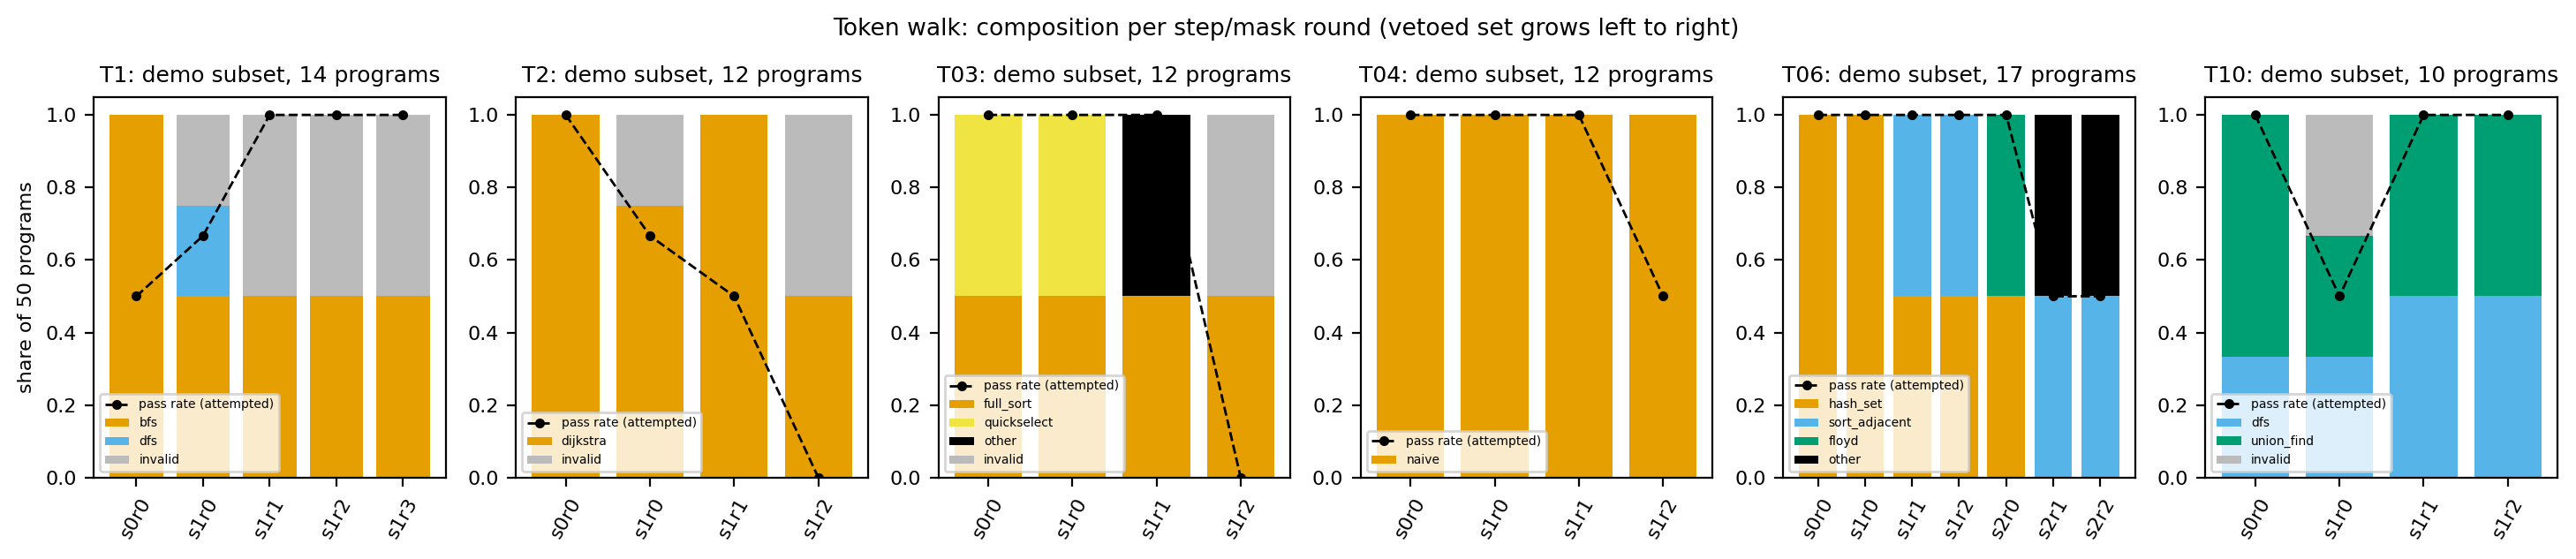


Figure (b) full run, 50 programs per bar: token-walk composition per step / mask round


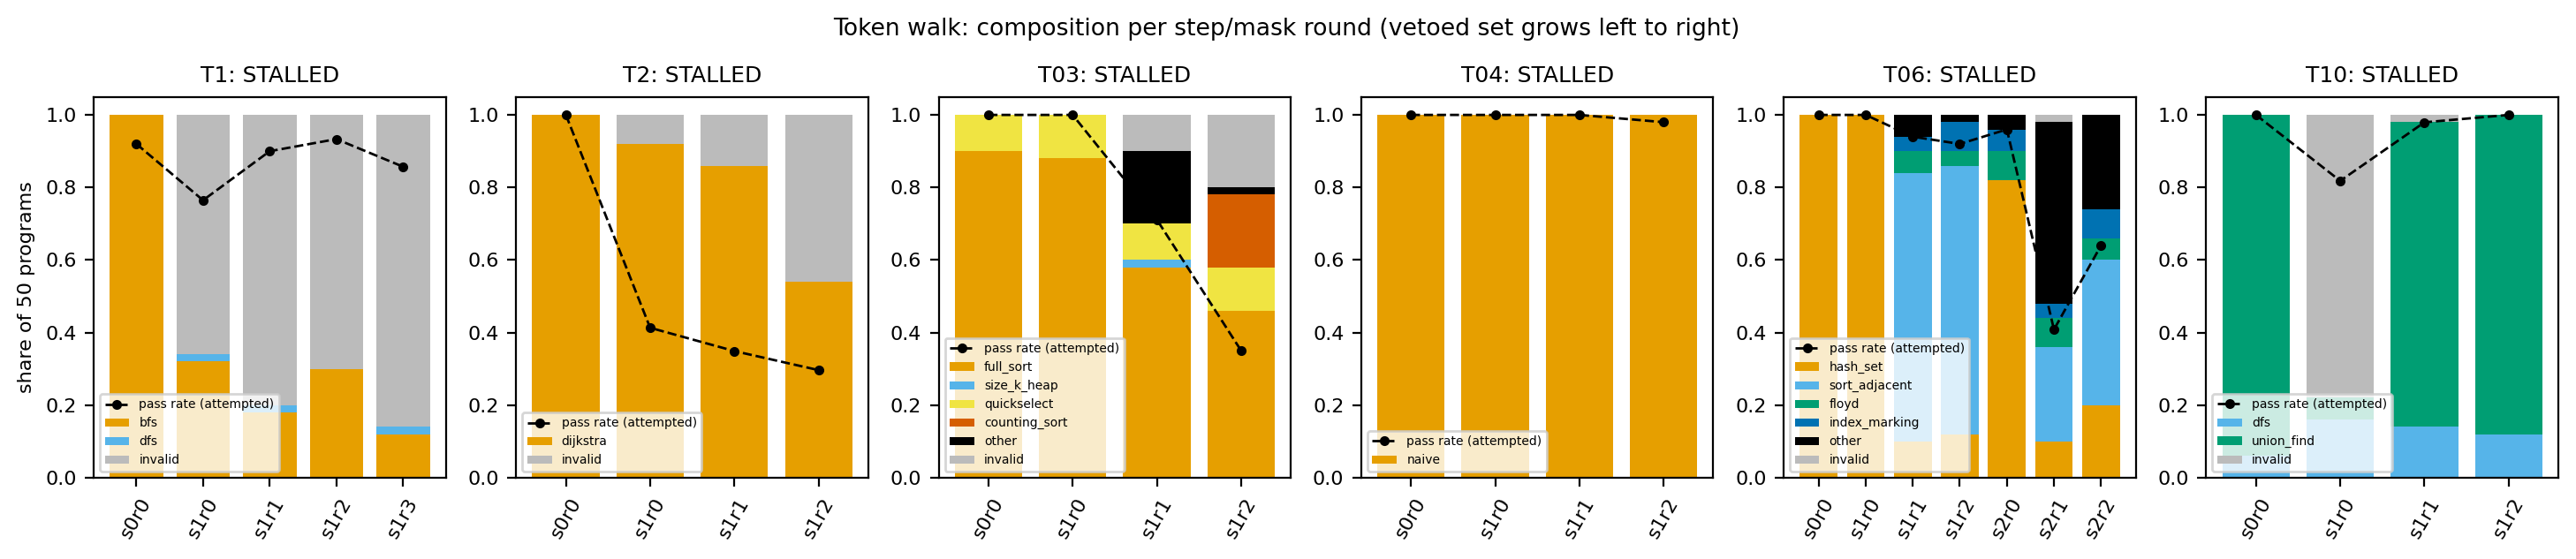


Figure (c) full run: sham vs distinctive n-gram veto


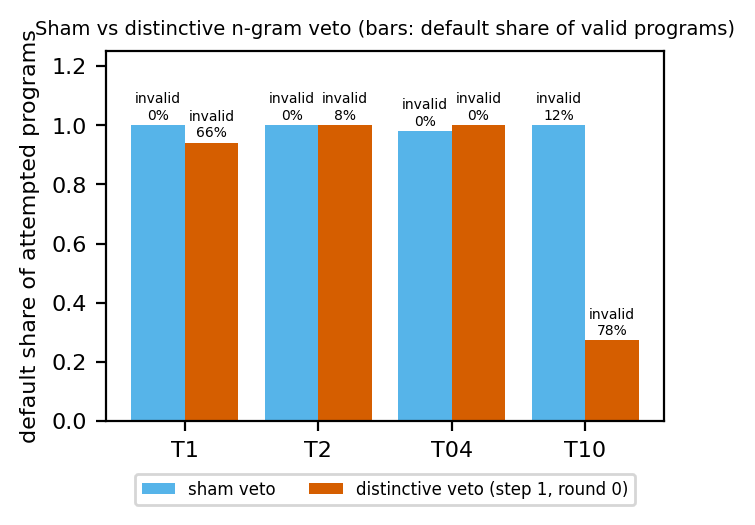

In [22]:
# ---- veto replay, per cell (demo subset)
print("VETO REPLAY (demo subset): per cell")
print(f"{'cell':<22}{'gens':>5}{'tokens':>8}{'emitted&masked':>16}{'banned seqs':>13}{'fires':>7}{'(stored)':>9}"
      f"{'leaks':>7}{'(stored)':>9}")
cells = {}
for x in replay:
    e = x["e"]
    cells.setdefault(f"{e['arm']}|{e['task']}|s{e['step']}r{e['round']}", []).append(x)
for c, xs in cells.items():
    print(f"{c:<22}{len(xs):>5}{sum(len(x['e']['raw_token_ids']) for x in xs):>8}"
          f"{sum(x['emitted_masked'] for x in xs):>16}{sum(x['occurrences'] for x in xs):>13}"
          f"{sum(x['fires'] for x in xs):>7}{sum(x['e']['fires'] for x in xs):>9}"
          f"{sum(x['leak']['leak'] for x in xs):>7}{sum(bool(x['e']['string_leak']) for x in xs):>9}")

# ---- walk status and the sham control (full run, results/walk.json)
print("\nTOKEN WALK (full run): status, vetoed set and the sham control")
for t in ALL_TASKS:
    w = full[t]
    sv = w["sham_vs_distinctive"]
    sham = (f"sham {sv['sham_ngram']!r}: default share {sv['sham_default_share']:.2f} (pass {sv['sham_pass_rate']:.2f})"
            f" vs distinctive {sv['distinctive_default_share']:.2f} (pass {sv['distinctive_pass_rate']:.2f}, "
            f"invalid {sv['distinctive_invalid_share']:.2f})" if "sham_ngram" in sv else f"sham {sv.get('status')}")
    print(f"{t:>3} {w['status']:<8} vetoed {str(w['vetoed']):<30} deepest rung {w['deepest_rung_reached']}  {sham}")
f5 = full["fixed_top5_T1"]
print(f"T1 fixed TOP5 veto {f5['targets']}: final round {f5['final_round']['counts']}; exp9 TOP5 prompt ban "
      f"avoidance {f5['exp9_TOP5_prompt_ban']['avoidance']}")

# ---- figures: (a) demo subset, (b) full run, (c) sham vs distinctive (full run)
for title, walk in (("(a) demo subset, 1-4 programs per bar (the y-axis label is the original function's)", demo_walk),
                    ("(b) full run, 50 programs per bar", full)):
    fig_walk(walk)
    print(f"\nFigure {title}: token-walk composition per step / mask round")
    display(Image(filename=str(FIGS / "fig1_token_walk.png"), width=1100))
fig_sham(full)
print("\nFigure (c) full run: sham vs distinctive n-gram veto")
display(Image(filename=str(FIGS / "fig5_sham_vs_distinctive.png"), width=520))

**Reading the results.** The veto does exactly what it promises: no banned sequence ever occurs in the output ids.
It still does not move Qwen3-8B off its default algorithm. Masking the distinctive n-gram removes a token sequence,
and the model rebuilds the same algorithm in one of three ways:
* through other tokens: a string leak, as in `queue.pop` written with a different last token;
* with renamed variables;
* as near-miss syntax, which shows up as the grey "invalid" share.

Extra mask rounds that add the leaked spans do not change the outcome, and the walk stalls. The sham control rules
out "any veto disrupts the model" as the explanation: a matched n-gram that the default shares with every other
algorithm leaves the default in place, valid and passing.

**Limits of this demo.**
* Labels and pass flags come from the stored labeller (runtime tracer, AST rules and an LLM judge) and are not
  recomputed here.
* The generations are not re-sampled: that needs vLLM and Qwen3-8B on a GPU.
* The demo uses 100 of the 1,750 token-walk programs.
* The prompt-reach (4a) and long-form (4c) datasets are not part of this demo.

To re-run everything, see the repository's README (`uv run method.py s0`, `... phase A`, `... analyze`,
`... outputs`).